# 03 · Prophet

Prophet models trend + daily/weekly/yearly seasonality + holidays + temperature (as heating and cooling degrees). It does **not** use recent load, so it answers: how much of demand is explained by calendar and weather alone?

The first attempt (linear trend) under-forecast badly on the test years. Load has been flat for 15 years, so this notebook also tries a **flat trend** and keeps whichever does better on the *validation* year (never on test).


In [ ]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))   # so "from src..." works from the notebooks folder


In [ ]:
import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from src.config import PROPHET_TRAIN_START
from src.features import load_features, add_groups, assign_split
from src.evaluate import summarize, error_by
from src.write_forecasts import write_forecasts

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "docs" / "results"; RES.mkdir(parents=True, exist_ok=True)

df = assign_split(add_groups(load_features()))
train = df[(df["split"] == "train") & (df["ts"] >= PROPHET_TRAIN_START)]
ev = df[df["split"].isin(["validation", "test"])].copy()
print(f"training rows: {len(train):,}  ({train['ts'].min()} -> {train['ts'].max()})")

training rows: 43,824  (2011-01-01 00:00:00 -> 2015-12-31 23:00:00)


## Prophet with a linear trend

In [ ]:
def to_prophet(d):
    return d.rename(columns={"ts": "ds", "load_mw": "y"})[["ds", "y", "hdd", "cdd"]]

def fit_prophet(growth):
    m = Prophet(growth=growth, daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=True)
    m.add_regressor("hdd")   # heating degrees
    m.add_regressor("cdd")   # cooling degrees
    m.add_country_holidays(country_name="US")
    t0 = time.time()
    m.fit(to_prophet(train))
    print(f"{growth} trend: fitted in {time.time() - t0:.0f}s")
    return m

m_lin = fit_prophet("linear")
fc_lin = m_lin.predict(to_prophet(ev).drop(columns="y"))
ev["prophet_linear_mw"] = fc_lin["yhat"].values

23:44:09 - cmdstanpy - INFO - Chain [1] start processing
23:45:09 - cmdstanpy - INFO - Chain [1] done processing


linear trend: fitted in 65s


## Is the bias a trend problem?

If the linear trend drifts away over the evaluation years while average load stays flat, the yearly bias will grow with distance from the training period.

trend moves -4,280 MW across the evaluation period


year
2016   -1280.0
2017   -2638.0
2018   -4422.0
Name: mean error (MW), linear trend, dtype: float64

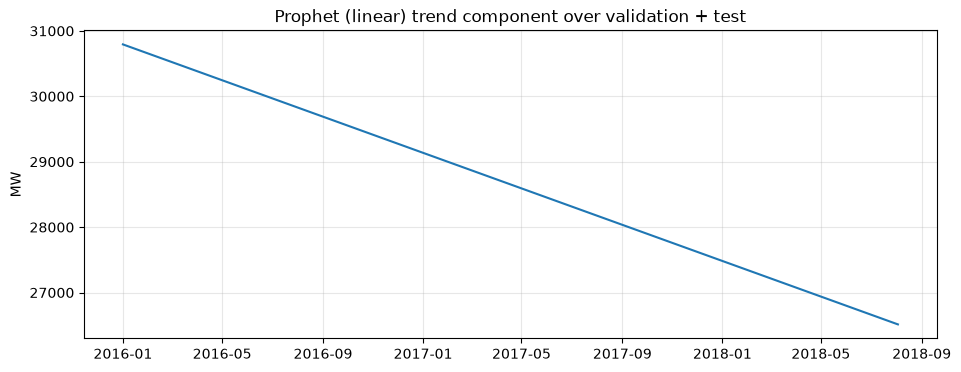

In [ ]:
fig, ax = plt.subplots()
ax.plot(fc_lin["ds"], fc_lin["trend"])
ax.set(title="Prophet (linear) trend component over validation + test", ylabel="MW")
fig.savefig(FIG / "prophet_trend_drift.png", dpi=150, bbox_inches="tight")
print(f"trend moves {fc_lin['trend'].iloc[-1] - fc_lin['trend'].iloc[0]:,.0f} MW across the evaluation period")

ev["err_linear"] = ev["prophet_linear_mw"] - ev["load_mw"]
ev.groupby("year")["err_linear"].mean().round(0).rename("mean error (MW), linear trend")

## Prophet with a flat trend

In [ ]:
m_flat = fit_prophet("flat")
fc_flat = m_flat.predict(to_prophet(ev).drop(columns="y"))
ev["prophet_flat_mw"] = fc_flat["yhat"].values

23:45:20 - cmdstanpy - INFO - Chain [1] start processing
23:45:22 - cmdstanpy - INFO - Chain [1] done processing


flat trend: fitted in 7s


## Compare against both baselines

`same_hour_yesterday` is a tougher benchmark than the official weekly baseline; the README should report both.

In [ ]:
ev["baseline_mw"] = ev["load_lag_168h"]
ev["yesterday_mw"] = ev["load_lag_24h"]

summary = pd.concat([
    summarize(ev, "baseline_mw", "seasonal_naive"),
    summarize(ev, "yesterday_mw", "same_hour_yesterday (benchmark)"),
    summarize(ev, "prophet_linear_mw", "prophet_linear"),
    summarize(ev, "prophet_flat_mw", "prophet_flat"),
])
summary.round(2)

,model,split,MAPE_%,WAPE_%,RMSE_MW,MAE_MW,bias_MW,n_hours,peak_MAE_MW,peak_bias_MW,peak_MAPE_%,peak_hour_within_1h_%,n_days
0,seasonal_naive,validation,10.24,10.60,4602.00,3323.27,-60.90,8783,4033.88,-60.16,10.55,73.70,365
1,seasonal_naive,test,10.99,11.30,4794.30,3511.52,-66.97,13895,4388.97,-111.60,11.80,64.53,578
0,same_hour_yesterday (benchmark),validation,6.57,6.65,2863.92,2084.36,-8.43,8783,2268.43,-1.81,6.13,71.78,365
1,same_hour_yesterday (benchmark),test,7.32,7.40,3134.38,2300.29,-14.98,13895,2618.00,-19.46,7.18,66.09,578
0,prophet_linear,validation,6.35,6.47,2631.13,2026.62,-1279.93,8783,2101.17,-1278.73,5.35,61.10,365
1,prophet_linear,test,11.26,11.22,4152.24,3486.12,-3296.90,13895,3160.33,-2929.97,8.38,56.75,578
0,prophet_flat,validation,5.75,5.61,2244.63,1757.67,549.16,8783,1902.42,590.40,5.28,60.27,365
1,prophet_flat,test,6.19,6.05,2376.11,1879.69,701.29,13895,2049.99,1115.31,5.88,56.57,578


In [ ]:
wape = summary.pivot(index="model", columns="split", values="WAPE_%")
wape["test_vs_seasonal_naive_%"] = (1 - wape["test"] / wape.loc["seasonal_naive", "test"]) * 100
wape["test_vs_yesterday_%"] = (1 - wape["test"] / wape.loc["same_hour_yesterday (benchmark)", "test"]) * 100
print("positive = better than that reference, negative = worse")
wape.round(2)

positive = better than that reference, negative = worse


split,test,validation,test_vs_seasonal_naive_%,test_vs_yesterday_%
model,,,,
prophet_flat,6.05,5.61,46.47,18.28
prophet_linear,11.22,6.47,0.72,-51.55
same_hour_yesterday (benchmark),7.40,6.65,34.49,0.00
seasonal_naive,11.30,10.60,0.00,-52.66


In [ ]:
# Pick the Prophet variant on VALIDATION WAPE only (test stays untouched).
val = summary[summary["split"] == "validation"].set_index("model")["WAPE_%"]
best = "prophet_linear" if val["prophet_linear"] <= val["prophet_flat"] else "prophet_flat"
ev["prophet_mw"] = ev["prophet_linear_mw" if best == "prophet_linear" else "prophet_flat_mw"]
print("chosen on validation WAPE:", best)

chosen on validation WAPE: prophet_flat


## Where does the chosen Prophet do well or badly?

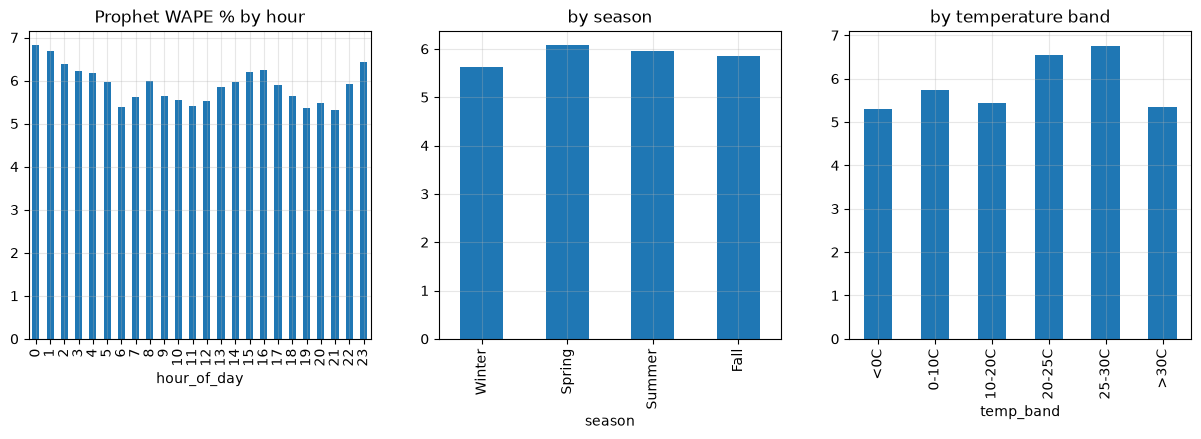

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
error_by(ev, "hour_of_day", "prophet_mw")["WAPE_%"].plot.bar(ax=axes[0], title="Prophet WAPE % by hour")
error_by(ev, "season", "prophet_mw")["WAPE_%"].reindex(["Winter", "Spring", "Summer", "Fall"]).plot.bar(ax=axes[1], title="by season")
error_by(ev, "temp_band", "prophet_mw")["WAPE_%"].plot.bar(ax=axes[2], title="by temperature band")
fig.savefig(FIG / "prophet_error_breakdown.png", dpi=150, bbox_inches="tight")

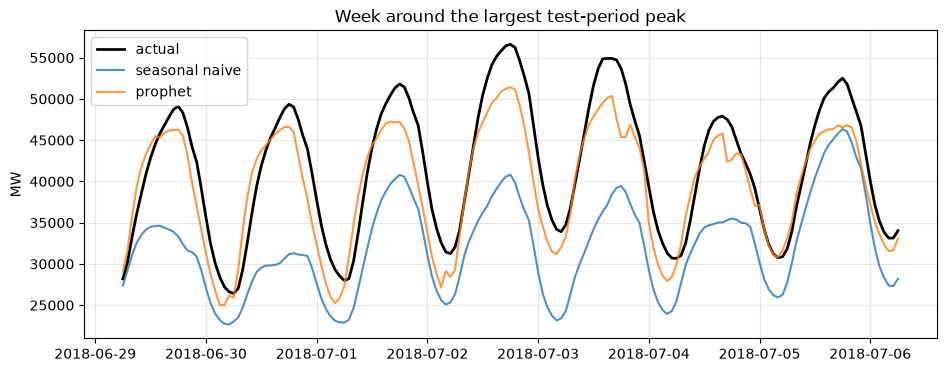

In [ ]:
t = ev[ev["split"] == "test"]
centre = t["load_mw"].idxmax()                        # the week around the biggest test peak
week = ev.loc[centre - 84: centre + 84]
fig, ax = plt.subplots()
ax.plot(week["ts"], week["load_mw"], label="actual", lw=2, color="black")
ax.plot(week["ts"], week["baseline_mw"], label="seasonal naive", alpha=0.8)
ax.plot(week["ts"], week["prophet_mw"], label="prophet", alpha=0.8)
ax.set(title="Week around the largest test-period peak", ylabel="MW"); ax.legend()
fig.savefig(FIG / "week_around_peak.png", dpi=150, bbox_inches="tight")

## Save Prophet forecasts and metrics

In [ ]:
n = write_forecasts(ev.assign(forecast_mw=ev["prophet_mw"]), "prophet")
print(f"wrote {n:,} rows to mart.fact_forecast (model: prophet = {best})")
summary.to_csv(RES / "week3_model_metrics.csv", index=False)

wrote 22,681 rows to mart.fact_forecast (model: prophet = prophet_flat)
